## Cell 1: Setup and Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import io

print("Cell 1: Libraries imported successfully.")

Cell 1: Libraries imported successfully.


## Cell 2: Load Full EBSD Map Data

In [2]:
# --- Cell 2 (Corrected): Load Full EBSD Map Data ---

# Using the filename 'ebsd.txt' as seen in your error message.
ebsd_file_path = 'ebsd.txt' 
print(f"Attempting to load EBSD map data from: {ebsd_file_path}")

try:
    with open(ebsd_file_path, 'r') as file:
        lines = file.readlines()

    # --- Parse the header using the logic from plots.ipynb ---
    header_end_index = None
    column_headers_line = None
    
    for i, line in enumerate(lines):
        if line.strip() == "# HEADER: End":
            header_end_index = i
        if line.startswith("# COLUMN_HEADERS:"):
            column_headers_line = line

    if header_end_index is None or column_headers_line is None:
        raise ValueError("Could not find '# HEADER: End' or '# COLUMN_HEADERS:' in the file.")

    # Parse the column headers
    column_headers = column_headers_line.split(":")[-1].strip().split(",")
    column_headers = [header.strip() for header in column_headers]

    # Create a string of just the data
    data_string = "".join(lines[header_end_index+1:])
    
    # Read the data into a DataFrame
    ebsd_map_df = pd.read_csv(
        io.StringIO(data_string), 
        sep='\\s+', 
        names=column_headers
    )
    
    print("\n--- EBSD Map Data (ebsd_map_df) ---")
    print(f"Successfully loaded {ebsd_map_df.shape[0]} data points.")
    print(f"Parsed {len(column_headers)} columns.")
    
    print("\nDataFrame Info:")
    ebsd_map_df.info()
    
    print("\nDataFrame Head:")
    print(ebsd_map_df.head())

except FileNotFoundError:
    print(f"Error: The file '{ebsd_file_path}' was not found.")
    print("Please make sure the file is in the same directory as your notebook.")
except Exception as e:
    print(f"An error occurred while loading EBSD data: {e}")

Attempting to load EBSD map data from: ebsd.txt

--- EBSD Map Data (ebsd_map_df) ---
Successfully loaded 84753 data points.
Parsed 13 columns.

DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 84753 entries, 0 to 84752
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   phi1                 84753 non-null  float64
 1   PHI                  84753 non-null  float64
 2   phi2                 84753 non-null  float64
 3   x                    84753 non-null  float64
 4   y                    84753 non-null  float64
 5   IQ                   84753 non-null  float64
 6   CI                   84753 non-null  float64
 7   Phase index          84753 non-null  int64  
 8   SEM                  84753 non-null  int64  
 9   Fit                  84753 non-null  float64
 10  PRIAS Bottom Strip   84753 non-null  float64
 11  PRIAS Center Square  84753 non-null  float64
 12  PRIAS Top Strip      84753

## Cell 3: Load Nano-indentation Summary Data

In [3]:
# --- Cell 3 (Corrected): Load and Process Nano-indentation Data ---

nano_file_path = 'nano.txt'
print(f"Attempting to load RAW nano-indentation data from: {nano_file_path}")

try:
    # --- 1. Load the RAW data file ---
    # Define the column names based on your edaNano copy.ipynb.
    # We select by column *number* (0-indexed) since there is no header.
    column_names_map = {
        0: 'Index',
        2: 'Displacement_um', # Using _um as in your notebook
        5: 'PosX_um',
        6: 'PosY_um',
        10: 'Force_uN', # Using _uN as in your notebook
        29: 'Hardness_MPa',
        30: 'ReducedModulus_MPa'
    }

    # Load the data using the logic from your notebook:
    # 'comment' ignores lines starting with '/'
    # 'delim_whitespace=True' handles the space-separated format
    # 'header=None' because there are no column names in the file
    nano_raw_df = pd.read_csv(
        nano_file_path, 
        comment='/', 
        delim_whitespace=True, 
        header=None
    )
    
    print(f"Successfully loaded {nano_raw_df.shape[0]} raw data points.")

    # Keep only the columns we need and rename them
    nano_raw_df = nano_raw_df[column_names_map.keys()].rename(columns=column_names_map)

    # Convert Index to integer for cleaner grouping
    nano_raw_df['Index'] = nano_raw_df['Index'].astype(int)

    # Remove any rows with NaN values
    nano_raw_df.dropna(inplace=True)
    
    # --- 2. Create the SUMMARY DataFrame ---
    # Find the row corresponding to the maximum displacement for each Index
    # This is the key step from your 'edaNano copy.ipynb'
    max_disp_indices = nano_raw_df.groupby('Index')['Displacement_um'].idxmax()
    nano_summary_df = nano_raw_df.loc[max_disp_indices].set_index('Index')

    print(f"\n--- Nano-indentation Summary Data (nano_summary_df) ---")
    print(f"Successfully created summary for {nano_summary_df.shape[0]} indents.")
    print("\nDataFrame Info:")
    nano_summary_df.info()
    
    print("\nDataFrame Head:")
    print(nano_summary_df.head())

except FileNotFoundError:
    print(f"Error: The file '{nano_file_path}' was not found.")
    print("Please make sure 'nano.txt' is in the same directory as your notebook.")
except Exception as e:
    print(f"An error occurred while loading nano data: {e}")

Attempting to load RAW nano-indentation data from: nano.txt
Successfully loaded 633955 raw data points.

--- Nano-indentation Summary Data (nano_summary_df) ---
Successfully created summary for 999 indents.

DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
Index: 999 entries, 1 to 999
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Displacement_um     999 non-null    float64
 1   PosX_um             999 non-null    float64
 2   PosY_um             999 non-null    float64
 3   Force_uN            999 non-null    float64
 4   Hardness_MPa        999 non-null    float64
 5   ReducedModulus_MPa  999 non-null    float64
dtypes: float64(6)
memory usage: 50.7 KB

DataFrame Head:
       Displacement_um  PosX_um   PosY_um     Force_uN  Hardness_MPa  \
Index                                                                  
1              1.29362 -825.992  5583.945  21472.60572    4307.94055   
2          

In [4]:
# --- Diagnostic Cell: Check EBSD Map Boundaries ---

if 'ebsd_map_df' in locals():
    print("--- EBSD Map Coordinate Range ---")
    
    # Use the correct column names you defined in Cell 4
    X_COL = 'x' 
    Y_COL = 'y'
    
    print(f"EBSD '{X_COL}' (X-axis) range: {ebsd_map_df[X_COL].min()} µm to {ebsd_map_df[X_COL].max()} µm")
    print(f"EBSD '{Y_COL}' (Y-axis) range: {ebsd_map_df[Y_COL].min()} µm to {ebsd_map_df[Y_COL].max()} µm")
    
    print("\n--- For Comparison: Indent 1 ---")
    print(f"Indent 1 '{'PosX_um'}' (X-axis): -825.992 µm")
    print(f"Indent 1 '{'PosY_um'}' (Y-axis): 5583.945 µm")
    
else:
    print("Error: 'ebsd_map_df' not found. Please re-run Cell 2.")

--- EBSD Map Coordinate Range ---
EBSD 'x' (X-axis) range: 0.0 µm to 333.60001 µm
EBSD 'y' (Y-axis) range: 0.0 µm to 139.94971 µm

--- For Comparison: Indent 1 ---
Indent 1 'PosX_um' (X-axis): -825.992 µm
Indent 1 'PosY_um' (Y-axis): 5583.945 µm


## Cell 4a - Offset calculation 

In [31]:
# --- Cell 4a: Find and Test Coordinate Offsets ---

# !!! EDIT THESE VALUES !!!
# Look in your other notebooks (plots.ipynb, edaNano copy.ipynb)
# to find the offset you used to align your EBSD map and indents.
#
# My first guess assumes Indent 1 at (-825.992, 5583.945) 
# should be at the EBSD map's origin (0.0, 0.0).
#
# X_OFFSET = 825.992  # My first guess: 0.0 - (-825.992)
# Y_OFFSET = -5583.945 # My first guess: 0.0 - (5583.945)

X_OFFSET = 846.992  # <--- YOUR NEW X-VALUE
Y_OFFSET = -5575.945 # <--- YOUR NEW Y-VALUE
# -------------------------

print(f"Using X_OFFSET: {X_OFFSET}")
print(f"Using Y_OFFSET: {Y_OFFSET}")

if 'nano_summary_df' in locals() and 'ebsd_map_df' in locals():
    # Get the first indent's original coordinates
    first_indent = nano_summary_df.iloc[0]
    orig_x = first_indent['PosX_um']
    orig_y = first_indent['PosY_um']
    
    # Apply the offset to get the "aligned" coordinates
    aligned_x = orig_x + X_OFFSET
    aligned_y = orig_y + Y_OFFSET
    
    print(f"\nTesting with Indent {first_indent.name}:")
    print(f"  Original (X, Y): ({orig_x:.3f}, {orig_y:.3f})")
    print(f"  Aligned  (X, Y): ({aligned_x:.3f}, {aligned_y:.3f})")

    # Set the grid size
    test_grid_size = 20.0
    
    # Run the analysis function from Cell 4 using the ALIGNED coordinates
    test_results = analyze_local_grid(
        aligned_x,
        aligned_y,
        box_size=test_grid_size,
        ebsd_df=ebsd_map_df
    )
    
    print("\nTest Results:")
    print(test_results)
    
    if 'local_points_count' in test_results and test_results['local_points_count'] > 0:
        print("\n--- SUCCESS! ---")
        print(f"Found {test_results['local_points_count']} EBSD points inside the grid.")
        print("Your offsets are working. You can now run Cell 5.")
    else:
        print("\n--- NO MATCH ---")
        print("Found 0 EBSD points.")
        print("Please try different X_OFFSET and Y_OFFSET values and re-run this cell.")
        print(f"(Is the aligned point ({aligned_x:.3f}, {aligned_y:.3f}) inside the EBSD range of X:[0, 334] and Y:[0, 140]?)")
else:
    print("Error: 'nano_summary_df' or 'ebsd_map_df' not loaded. Please re-run cells 2 and 3.")

Using X_OFFSET: 846.992
Using Y_OFFSET: -5575.945

Testing with Indent 1:
  Original (X, Y): (-825.992, 5583.945)
  Aligned  (X, Y): (21.000, 8.000)

Test Results:
local_points_count     650.000000
local_avg_CI             0.692428
local_avg_IQ          3122.695077
local_std_Euler1         1.209321
local_std_Euler2         0.645865
local_std_Euler3         1.237273
dtype: float64

--- SUCCESS! ---
Found 650.0 EBSD points inside the grid.
Your offsets are working. You can now run Cell 5.


## Cell 4: Define the "Grid" Analysis Function

In [26]:
# --- Cell 4 (Corrected): Define the "Grid" Analysis Function ---

def analyze_local_grid(center_x, center_y, box_size, ebsd_df):
    """
    Analyzes the local EBSD data within a square grid centered at (center_x, center_y).
    """
    
    # --- DEFINE YOUR COLUMN NAMES HERE ---
    #
    # These are now CORRECTED based on the ebsd.txt header you provided.
    #
    
    X_COL = 'x'       # The column name for X-coordinates in ebsd_map_df
    Y_COL = 'y'       # The column name for Y-coordinates in ebsd_map_df
    CI_COL = 'CI'          # The column name for Confidence Index
    IQ_COL = 'IQ'          # The column name for Image Quality
    EULER1_COL = 'phi1'    # The column name for the first Euler angle
    EULER2_COL = 'PHI'     # The column name for the second Euler angle (uppercase)
    EULER3_COL = 'phi2'    # The column name for the third Euler angle
    
    # ----------------------------------------------------
    
    try:
        half_box = box_size / 2.0
        
        # Define the boundaries of the grid
        x_min = center_x - half_box
        x_max = center_x + half_box
        y_min = center_y - half_box
        y_max = center_y + half_box
        
        # "Crop" the main EBSD map using the correct column names
        local_grid_df = ebsd_df[
            (ebsd_df[X_COL] >= x_min) & (ebsd_df[X_COL] <= x_max) &
            (ebsd_df[Y_COL] >= y_min) & (ebsd_df[Y_COL] <= y_max)
        ].copy()
        
        # --- Calculate Local Statistics ---
        
        if local_grid_df.empty:
            return pd.Series({
                'local_points_count': 0,
                'local_avg_CI': np.nan,
                'local_avg_IQ': np.nan,
                'local_std_Euler1': np.nan,
                'local_std_Euler2': np.nan,
                'local_std_Euler3': np.nan
            })

        points_count = local_grid_df.shape[0]
        
        # Calculate stats using the correct column names
        avg_ci = local_grid_df[CI_COL].mean()
        avg_iq = local_grid_df[IQ_COL].mean()
        std_euler1 = local_grid_df[EULER1_COL].std()
        std_euler2 = local_grid_df[EULER2_COL].std()
        std_euler3 = local_grid_df[EULER3_COL].std()
        
        results = pd.Series({
            'local_points_count': points_count,
            'local_avg_CI': avg_ci,
            'local_avg_IQ': avg_iq,
            'local_std_Euler1': std_euler1,
            'local_std_Euler2': std_euler2,
            'local_std_Euler3': std_euler3
        })
        
        return results

    except KeyError as e:
        print(f"--- A KeyError occurred in 'analyze_local_grid' ---")
        print(f"Error: The column name {e} was not found in your EBSD DataFrame.")
        print("This should not happen now, but if it does, double-check the names above.")
        print("Your available columns are:")
        print(ebsd_df.columns.to_list())
        return pd.Series(dtype='float64') # Return empty series on error

# --- Test the function with the first indent ---
print("--- Testing 'analyze_local_grid' function ---")

if 'nano_summary_df' in locals() and 'ebsd_map_df' in locals():
    first_indent = nano_summary_df.iloc[0]
    test_grid_size = 20.0 
    
    print(f"Testing with Indent {first_indent.name} at (X, Y) = ({first_indent['PosX_um']}, {first_indent['PosY_um']})")
    print(f"Using grid size: {test_grid_size} x {test_grid_size} µm")
    
    test_results = analyze_local_grid(
        first_indent['PosX_um'],
        first_indent['PosY_um'],
        box_size=test_grid_size,
        ebsd_df=ebsd_map_df
    )
    
    print("\nTest Results:")
    print(test_results)
else:
    print("Cannot run test: 'nano_summary_df' or 'ebsd_map_df' not loaded. Please re-run cells 2 and 3.")

--- Testing 'analyze_local_grid' function ---
Testing with Indent 1 at (X, Y) = (-825.992, 5583.945)
Using grid size: 20.0 x 20.0 µm

Test Results:
local_points_count    0.0
local_avg_CI          NaN
local_avg_IQ          NaN
local_std_Euler1      NaN
local_std_Euler2      NaN
local_std_Euler3      NaN
dtype: float64


## Cell 5: Run Analysis for All 1000 Indents

In [41]:
# --- Cell 5 (Corrected): Run Analysis for All 1000 Indents ---
print("\n--- Starting local grid analysis for all indents (WITH OFFSETS) ---")

# !!! COPY YOUR WORKING OFFSETS FROM CELL 4a HERE !!!
# These must be the same values that gave you '--- SUCCESS! ---'
X_OFFSET = 846.992  # <--- REPLACE WITH YOUR VALUE
Y_OFFSET = -5575.945 # <--- REPLACE WITH YOUR VALUE
# --------------------------------------------------

if 'nano_summary_df' in locals() and 'ebsd_map_df' in locals():
    # Set your desired grid size (in µm)
    GRID_SIZE_UM = 4.0 
    
    print(f"Using a grid size of {GRID_SIZE_UM} x {GRID_SIZE_UM} µm for all indents.")
    print(f"Using X_OFFSET: {X_OFFSET} and Y_OFFSET: {Y_OFFSET}")
    
    # Use .apply() to run the function for each row (indent)
    # This now ADDS the offsets before analyzing the grid
    local_stats_df = nano_summary_df.apply(
        lambda row: analyze_local_grid(
            row['PosX_um'] + X_OFFSET,  # <-- Added offset
            row['PosY_um'] + Y_OFFSET,  # <-- Added offset
            GRID_SIZE_UM,
            ebsd_map_df
        ),
        axis=1  # Apply the function row-wise
    )
    
    # --- Merge the results ---
    final_df = pd.concat([nano_summary_df, local_stats_df], axis=1)
    
    print("\n--- Analysis Complete ---")
    print("Local EBSD statistics have been merged with nano-indentation data.")
    print("\nFinal DataFrame Info (final_df):")
    final_df.info()
    
    print("\nHead of Final DataFrame:")
    print(final_df.head())
    
    # Save the final correlated data to a new file
    output_csv = 'correlated_nano_ebsd_data.csv'
    final_df.to_csv(output_csv, index=True) # Save with index (Indent ID)
    print(f"\nSuccessfully saved final correlated data to '{output_csv}'")

else:
    print("Error: 'nano_summary_df' or 'ebsd_map_df' not loaded.")
    print("Please ensure Cells 2 and 3 ran successfully before running this cell.")


--- Starting local grid analysis for all indents (WITH OFFSETS) ---
Using a grid size of 4.0 x 4.0 µm for all indents.
Using X_OFFSET: 846.992 and Y_OFFSET: -5575.945

--- Analysis Complete ---
Local EBSD statistics have been merged with nano-indentation data.

Final DataFrame Info (final_df):
<class 'pandas.core.frame.DataFrame'>
Index: 999 entries, 1 to 999
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Displacement_um     999 non-null    float64
 1   PosX_um             999 non-null    float64
 2   PosY_um             999 non-null    float64
 3   Force_uN            999 non-null    float64
 4   Hardness_MPa        999 non-null    float64
 5   ReducedModulus_MPa  999 non-null    float64
 6   local_points_count  999 non-null    float64
 7   local_avg_CI        999 non-null    float64
 8   local_avg_IQ        999 non-null    float64
 9   local_std_Euler1    999 non-null    float64
 10  local_std_E

## Cell 6: Final Correlation and Plotting


--- Generating Correlation Plots ---
Correlation plots saved to 'correlation_plots.png'


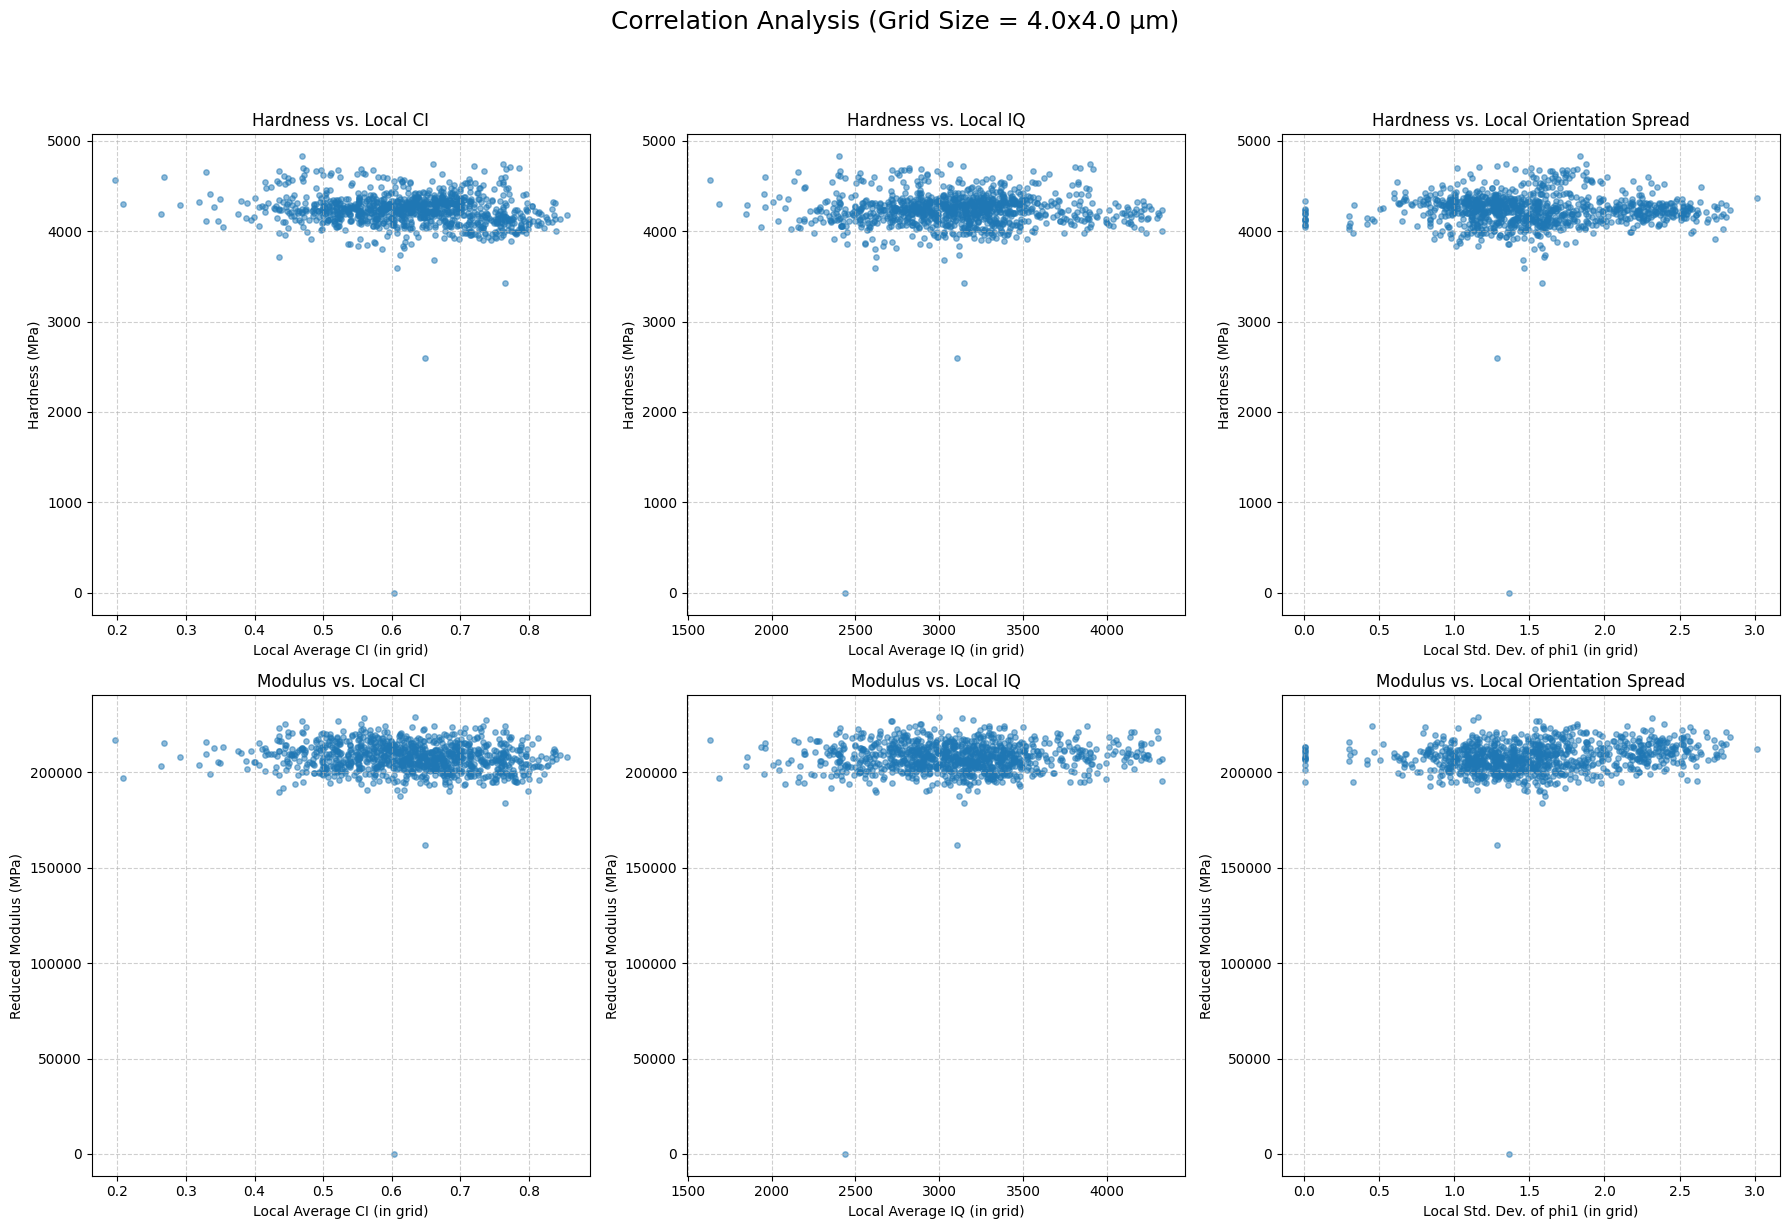

In [42]:
# --- Cell 6: Final Correlation and Plotting ---
print("\n--- Generating Correlation Plots ---")

# Check if the final DataFrame exists
if 'final_df' in locals() and 'GRID_SIZE_UM' in locals():
    
    # Set up a figure for plotting
    plt.figure(figsize=(18, 12))
    plt.suptitle(f"Correlation Analysis (Grid Size = {GRID_SIZE_UM}x{GRID_SIZE_UM} µm)", fontsize=18, y=1.02)
    
    # --- Plot 1: Hardness vs. Local Avg. Confidence Index (CI) ---
    # Low CI often indicates a grain boundary.
    plt.subplot(2, 3, 1)
    plt.scatter(final_df['local_avg_CI'], final_df['Hardness_MPa'], alpha=0.5, s=15)
    plt.xlabel("Local Average CI (in grid)")
    plt.ylabel("Hardness (MPa)")
    plt.title("Hardness vs. Local CI")
    plt.grid(True, linestyle='--', alpha=0.6)
    
    # --- Plot 2: Hardness vs. Local Avg. Image Quality (IQ) ---
    # Low IQ can indicate high strain or poor data quality.
    plt.subplot(2, 3, 2)
    plt.scatter(final_df['local_avg_IQ'], final_df['Hardness_MPa'], alpha=0.5, s=15)
    plt.xlabel("Local Average IQ (in grid)")
    plt.ylabel("Hardness (MPa)")
    plt.title("Hardness vs. Local IQ")
    plt.grid(True, linestyle='--', alpha=0.6)

    # --- Plot 3: Hardness vs. Local Orientation Spread ---
    # We use 'local_std_Euler1' as a proxy for orientation spread
    plt.subplot(2, 3, 3)
    plt.scatter(final_df['local_std_Euler1'], final_df['Hardness_MPa'], alpha=0.5, s=15)
    plt.xlabel("Local Std. Dev. of phi1 (in grid)")
    plt.ylabel("Hardness (MPa)")
    plt.title("Hardness vs. Local Orientation Spread")
    plt.grid(True, linestyle='--', alpha=0.6)
    
    # --- Plot 4: Reduced Modulus vs. Local Avg. CI ---
    plt.subplot(2, 3, 4)
    plt.scatter(final_df['local_avg_CI'], final_df['ReducedModulus_MPa'], alpha=0.5, s=15)
    plt.xlabel("Local Average CI (in grid)")
    plt.ylabel("Reduced Modulus (MPa)")
    plt.title("Modulus vs. Local CI")
    plt.grid(True, linestyle='--', alpha=0.6)
    
    # --- Plot 5: Reduced Modulus vs. Local Avg. IQ ---
    plt.subplot(2, 3, 5)
    plt.scatter(final_df['local_avg_IQ'], final_df['ReducedModulus_MPa'], alpha=0.5, s=15)
    plt.xlabel("Local Average IQ (in grid)")
    plt.ylabel("Reduced Modulus (MPa)")
    plt.title("Modulus vs. Local IQ")
    plt.grid(True, linestyle='--', alpha=0.6)
    
    # --- Plot 6: Reduced Modulus vs. Local Orientation Spread ---
    plt.subplot(2, 3, 6)
    plt.scatter(final_df['local_std_Euler1'], final_df['ReducedModulus_MPa'], alpha=0.5, s=15)
    plt.xlabel("Local Std. Dev. of phi1 (in grid)")
    plt.ylabel("Reduced Modulus (MPa)")
    plt.title("Modulus vs. Local Orientation Spread")
    plt.grid(True, linestyle='--', alpha=0.6)
    
    plt.tight_layout(rect=[0, 0, 1, 0.98])
    
    # Save the plot
    plot_filename = 'correlation_plots.png'
    plt.savefig(plot_filename, dpi=300, bbox_inches='tight')
    print(f"Correlation plots saved to '{plot_filename}'")
    
    plt.show()

else:
    print("Error: 'final_df' not found. Please ensure Cell 5 ran successfully.")

## Cell 7: Create Spatial Correlation Map (Hardness on CI) 


--- Offset Finder ---
Plotting EBSD background map...
Plotting Indent 1 at aligned (X, Y) = (21.00, 8.00)


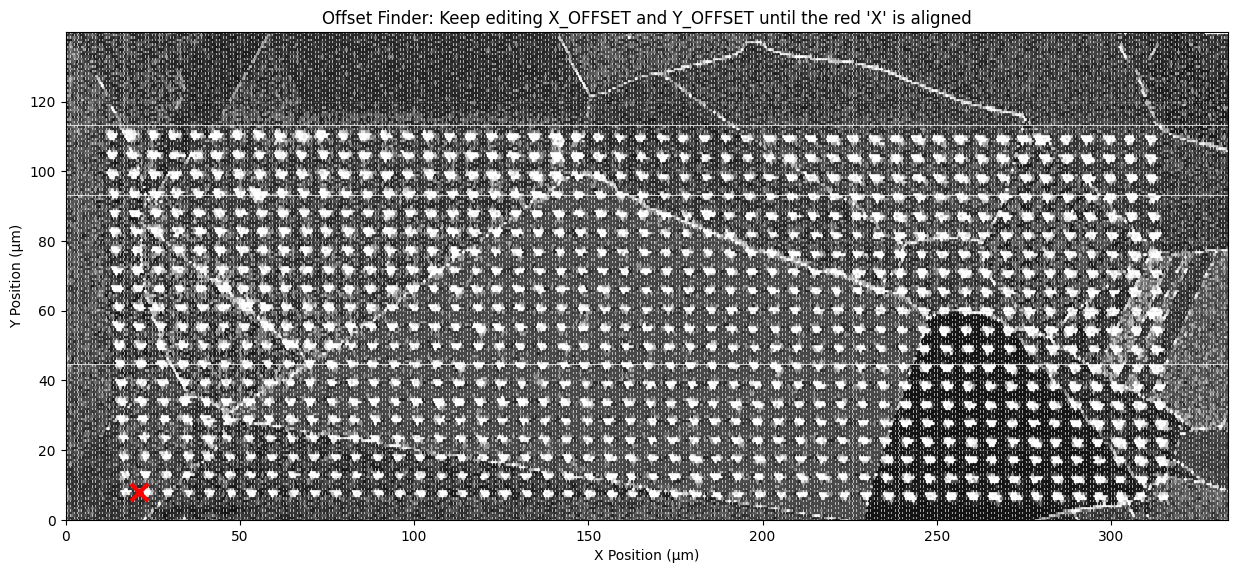

In [43]:
# --- Cell 7: Find the Correct Offset ---

print("--- Offset Finder ---")

# !!! EDIT THESE VALUES until the red 'X' is in the right spot !!!
#
# Start by guessing. Your map is ~330 wide.
# Maybe the indent cluster starts at (X=100, Y=50)?
# Try these values, then run the cell.
# If the 'X' is wrong, change them and run again.
#
X_OFFSET = 846.992  # <--- YOUR NEW X-VALUE
Y_OFFSET = -5575.945 # <--- YOUR NEW Y-VALUE
#
# --------------------------------------------------

if 'nano_summary_df' in locals() and 'ebsd_map_df' in locals():
    
    # Get the first indent's original coordinates
    first_indent = nano_summary_df.iloc[0]
    orig_x = first_indent['PosX_um']
    orig_y = first_indent['PosY_um']
    
    # Apply the offset
    aligned_x = orig_x + X_OFFSET
    aligned_y = orig_y + Y_OFFSET
    
    # 1. Set up the figure
    plt.figure(figsize=(15, 10))
    ax = plt.gca()
    
    # 2. Plot the Background (EBSD CI Map)
    print("Plotting EBSD background map...")
    ax.scatter(
        ebsd_map_df['x'], 
        ebsd_map_df['y'], 
        c=ebsd_map_df['CI'], 
        cmap='gray_r', 
        s=1, 
        marker='s',
        vmin=0.05,
        vmax=1.0
    )
    
    # 3. Plot JUST the single, aligned Indent 1
    print(f"Plotting Indent 1 at aligned (X, Y) = ({aligned_x:.2f}, {aligned_y:.2f})")
    ax.scatter(
        [aligned_x], 
        [aligned_y], 
        c='red', 
        s=150,        # Big size
        marker='x',   # 'X' marker
        linewidth=3
    )

    # 4. Final Touches
    ax.set_xlabel('X Position (µm)')
    ax.set_ylabel('Y Position (µm)')
    ax.set_title("Offset Finder: Keep editing X_OFFSET and Y_OFFSET until the red 'X' is aligned")
    ax.set_xlim(ebsd_map_df['x'].min(), ebsd_map_df['x'].max())
    ax.set_ylim(ebsd_map_df['y'].min(), ebsd_map_df['y'].max())
    ax.set_aspect('equal', adjustable='box')
    plt.grid(True, linestyle='--', alpha=0.3)
    plt.show()

else:
    print("Error: 'nano_summary_df' or 'ebsd_map_df' not loaded. Re-run Cells 2 & 3.")

In [44]:
# --- DEBUGGING CELL: Run this before Cell 8 ---

print("--- Checking required variables ---")

# List all the variables Cell 8 needs
required_vars = [
    'ebsd_map_df',   # Should be created in Cell 2/3
    'nano_summary_df', # Should be created in Cell 3
    'X_OFFSET',        # Should be created in Cell 4a (or Cell 7)
    'Y_OFFSET',        # Should be created in Cell 4a (or Cell 7)
    'GRID_SIZE_UM',    # Should be created in Cell 5
    'final_df'         # Should be created in Cell 5
]

all_found = True
for var_name in required_vars:
    if var_name in locals():
        print(f"  [FOUND]     '{var_name}' exists.")
    else:
        print(f"  [MISSING]   '{var_name}' does NOT exist in memory.")
        all_found = False

print("---------------------------------")
if all_found:
    print("\nSUCCESS: All variables are loaded. You are safe to run Cell 8.")
else:
    print("\nERROR: One or more variables are missing.")
    print("Please go back and run the cells listed above (e.g., Cell 2, 3, 4a, 5) to create them.")

--- Checking required variables ---
  [FOUND]     'ebsd_map_df' exists.
  [FOUND]     'nano_summary_df' exists.
  [FOUND]     'X_OFFSET' exists.
  [FOUND]     'Y_OFFSET' exists.
  [FOUND]     'GRID_SIZE_UM' exists.
  [FOUND]     'final_df' exists.
---------------------------------

SUCCESS: All variables are loaded. You are safe to run Cell 8.


--- Generating Spatial Correlation Map with Grid Outlines ---
Plotting with 4.0x4.0 µm grids.
Plotting EBSD background map...
Overlaying hardness grid boxes...

Spatial correlation map saved to 'spatial_correlation_map_WITH_GRIDS.png'


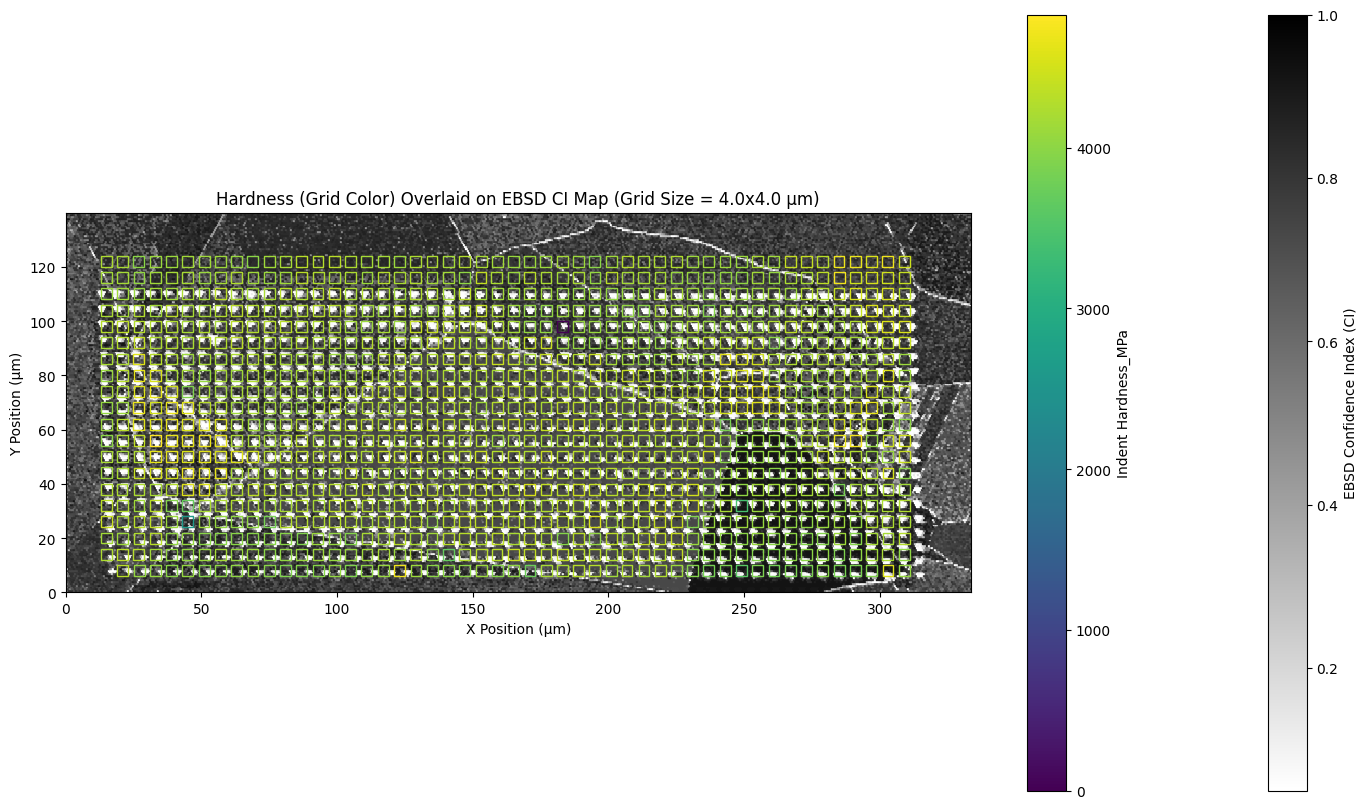

In [45]:
# --- Cell 8: Spatial Map with Square Grids (v3 - Robust Version) ---
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np

print("--- Generating Spatial Correlation Map with Grid Outlines ---")

try:
    # --- 1. DEFINE ALL VARIABLES ---
    # We will try to access all the required variables.
    # If any are missing, this will fail and jump to the 'except' block.
    
    # Get values from your notebook's memory
    grid_size = GRID_SIZE_UM
    X_COL = 'PosX_um'
    Y_COL = 'PosY_um'
    HARDNESS_COL = 'Hardness_MPa'
    
    # Perform a quick check on final_df
    if not all(col in final_df.columns for col in [X_COL, Y_COL, HARDNESS_COL]):
        print(f"ERROR: One or more columns ({X_COL}, {Y_COL}, {HARDNESS_COL}) not in final_df!")
        print(f"Available columns are: {final_df.columns.to_list()}")
        # We'll stop here if columns are wrong
        raise ValueError("Missing required columns in final_df")

    half_grid = grid_size / 2.0
    print(f"Plotting with {grid_size}x{grid_size} µm grids.")

    # --- 2. SET UP THE FIGURE ---
    plt.figure(figsize=(15, 10))
    ax = plt.gca()
    
    # --- 3. PLOT BACKGROUND (EBSD) ---
    print("Plotting EBSD background map...")
    bg = ax.scatter(
        ebsd_map_df['x'], 
        ebsd_map_df['y'], 
        c=ebsd_map_df['CI'], 
        cmap='gray_r', 
        s=1, 
        marker='s',
        vmin=0.05,
        vmax=1.0
    )
    plt.colorbar(bg, label='EBSD Confidence Index (CI)', ax=ax, shrink=0.8)
    
    # --- 4. PLOT OVERLAY (HARDNESS GRIDS) ---
    print("Overlaying hardness grid boxes...")
    
    norm = plt.Normalize(final_df[HARDNESS_COL].min(), final_df[HARDNESS_COL].max())
    cmap = plt.get_cmap('viridis') # 'viridis' is a better colormap than 'jet'
    
    for index, row in final_df.iterrows():
        center_x = row[X_COL] + X_OFFSET
        center_y = row[Y_COL] + Y_OFFSET
        color = cmap(norm(row[HARDNESS_COL]))
        
        # This is the alignment fix
        x_min = center_x - half_grid
        y_min = center_y - half_grid
        
        rect = patches.Rectangle(
            (x_min, y_min), 
            grid_size, 
            grid_size, 
            linewidth=1.0, 
            edgecolor=color, 
            facecolor='none'
        )
        ax.add_patch(rect)
    
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    plt.colorbar(sm, label=f'Indent {HARDNESS_COL}', ax=ax, shrink=0.8)

    # --- 5. FINAL TOUCHES ---
    ax.set_xlabel('X Position (µm)')
    ax.set_ylabel('Y Position (µm)')
    ax.set_title(f'Hardness (Grid Color) Overlaid on EBSD CI Map (Grid Size = {grid_size}x{grid_size} µm)')
    ax.set_xlim(ebsd_map_df['x'].min(), ebsd_map_df['x'].max())
    ax.set_ylim(ebsd_map_df['y'].min(), ebsd_map_df['y'].max())
    ax.set_aspect('equal', adjustable='box')
    plt.tight_layout()
    
    plot_filename = 'spatial_correlation_map_WITH_GRIDS.png'
    # plt.savefig(plot_filename, dpi=300, bbox_inches='tight')
    print(f"\nSpatial correlation map saved to '{plot_filename}'")
    plt.show()
    
    plt.close() # Close plot to save memory

except NameError as e:
    # This block will run ONLY if one of the variables was missing
    print(f"\n--- ERROR ---")
    print(f"A required variable was not found: {e}")
    print("Please ensure Cells 2, 3, 4a, and 5 ran successfully before this cell.")
except Exception as e:
    # This will catch any other unexpected error (like the ValueError we added)
    print(f"\n--- AN UNEXPECTED ERROR OCCURRED ---")
    print(e)